# Distância até o Rio Capibaribe

In [1]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from scipy.ndimage import distance_transform_edt
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from pyproj import Transformer
import numpy as np

## Criar mapa raster de distância

In [3]:
RIO = '../dados/capibaribe/Rio_Principal_CAP_25S.shp'
MOLDURA = '../dados/rasters/moldura-recife.tif'
SAIDA = '../dados/rasters/distancia_rio_recife.tif'


with rasterio.open(MOLDURA) as src:
    profile = src.profile.copy()
    transform = src.transform
    width = src.width
    height = src.height
    crs = src.crs
    pixel_size_x = abs(transform.a)
    pixel_size_y = abs(transform.e)

    print(f"CRS: {crs}")
    print(f"Resolução: {pixel_size_x} x {pixel_size_y} m")
    print(f"Dimensão: {width} x {height}")


rios = gpd.read_file(RIO)
rios = rios.to_crs(crs)

rio_raster = rasterize(
    [(geom, 1) for geom in rios.geometry if geom is not None],
    out_shape=(height, width),
    transform=transform,
    fill=0,
    dtype="uint8"
)

distancia_pixels = distance_transform_edt(rio_raster == 0)


# Converter distância de pixels para metros
distancia_metros = distancia_pixels * pixel_size_x

profile.update(
    dtype="float32",
    count=1,
    nodata=-9999,
    compress="lzw"
)

with rasterio.open(SAIDA, "w", **profile) as dst:
    dst.write(distancia_metros.astype("float32"), 1)

print(f"Raster criado: {SAIDA}")

CRS: EPSG:31985
Resolução: 30.0 x 30.0 m
Dimensão: 646 x 898
Raster criado: ../dados/rasters/distancia_rio_recife.tif


## Visualizar raster de distância

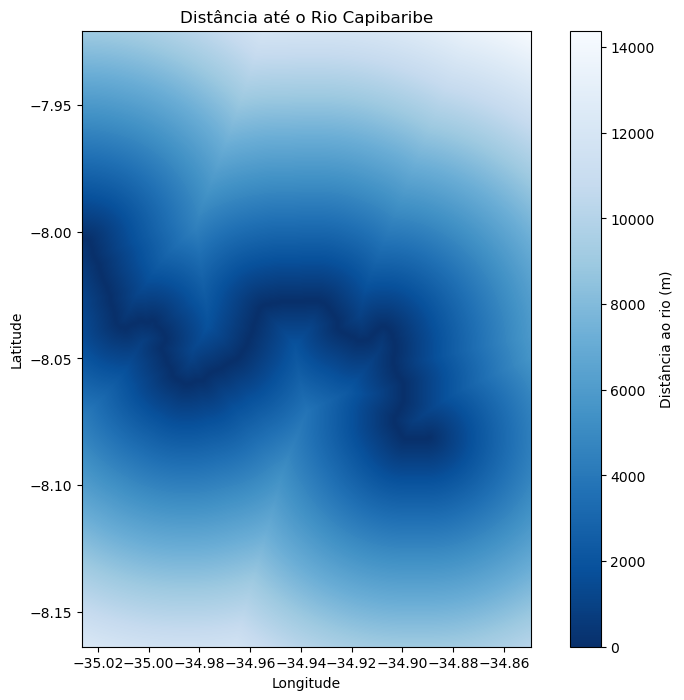

In [4]:
with rasterio.open(SAIDA) as src:
    raster = src.read(1)

    left = src.bounds.left
    right = src.bounds.right
    bottom = src.bounds.bottom
    top = src.bounds.top

    crs = src.crs


# Converter coordenadas dos cantos para Longitude/Latitude
transformer = Transformer.from_crs(
    crs,
    "EPSG:4326",
    always_xy=True
)

lon_min, lat_min = transformer.transform(left, bottom)
lon_max, lat_max = transformer.transform(right, top)


plt.figure(figsize=(10, 8))

plt.imshow(
    raster,
    extent=[
        lon_min,
        lon_max,
        lat_min,
        lat_max
    ],
    origin="upper",
    cmap="Blues_r",
    norm=Normalize(
        vmin=0,
        vmax=raster.max()
    )
)

plt.colorbar(label="Distância ao rio (m)")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Distância até o Rio Capibaribe")

plt.show()

## Reclassificar raster de distância

In [5]:
SAIDA_RECLASS = "../dados/rasters/distancia_rio_recife_reclass.tif"

with rasterio.open(SAIDA) as src:

    distancia = src.read(1)
    profile = src.profile.copy()
    nodata = src.nodata
    risco = np.zeros(distancia.shape, dtype=np.uint8)

    risco[(distancia >= 0) & (distancia <= 100)] = 4
    risco[(distancia > 100) & (distancia <= 250)] = 3
    risco[(distancia > 250) & (distancia <= 500)] = 2
    risco[(distancia > 500) & (distancia <= 1000)] = 1
    risco[distancia > 1000] = 0

    if nodata is not None:
        risco[distancia == nodata] = 255

    profile.update(
        dtype="uint8",
        count=1,
        nodata=255,
        compress="lzw"
    )

    with rasterio.open(SAIDA_RECLASS, "w", **profile) as dst:
        dst.write(risco, 1)

print(f"Raster criado: {SAIDA_RECLASS}")

Raster criado: ../dados/rasters/distancia_rio_recife_reclass.tif


## Visualizar raster de distância reclassificado

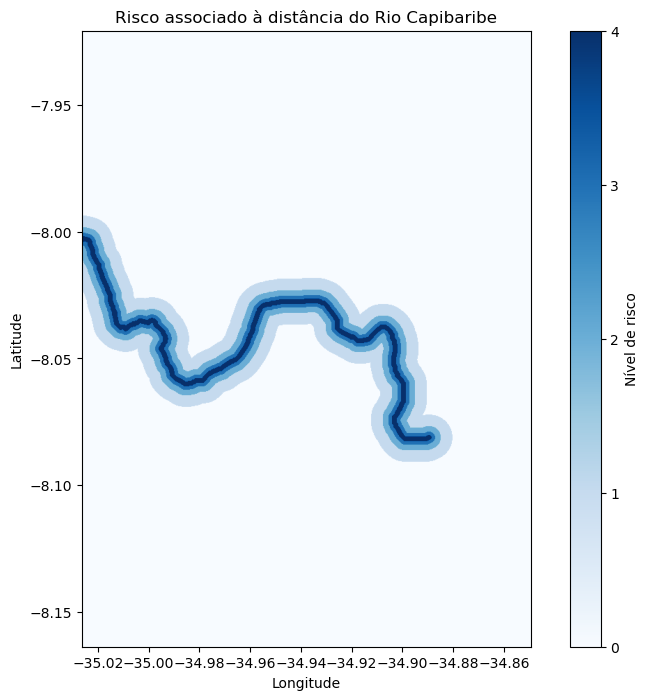

In [6]:
with rasterio.open(SAIDA_RECLASS) as src:

    raster = src.read(1)

    left = src.bounds.left
    right = src.bounds.right
    bottom = src.bounds.bottom
    top = src.bounds.top

    transformer = Transformer.from_crs(
        src.crs,
        "EPSG:4326",
        always_xy=True
    )

    lon_min, lat_min = transformer.transform(left, bottom)
    lon_max, lat_max = transformer.transform(right, top)

plt.figure(figsize=(10, 8))

plt.imshow(
    raster,
    extent=[
        lon_min,
        lon_max,
        lat_min,
        lat_max
    ],
    origin="upper",
    cmap="Blues",
)

cbar = plt.colorbar(
    ticks=[0, 1, 2, 3, 4]
)

cbar.set_label("Nível de risco")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Risco associado à distância do Rio Capibaribe")

plt.show()